# Part 3C: Out-of-sample effectiveness

## Restating the question

Keep the three sets of 3A weights **unchanged** and switch to data the optimizer **has never seen**, **2005/01 – 2023/07** (223 months), to compute the annualized volatility each realizes:

- Which portfolio has the lowest realized volatility, and which the highest?
- Is this ordering "as expected"? In the context of what was covered on optimization in class, why might this be the case?


## Method (identical to 3B, only the period changes)

1. Monthly portfolio return $r_{p,t} = w^\top r_t$, with $w$ fixed at the 3A weights (rebalanced monthly to the target weights, no re-estimation);
2. Annualized volatility = sample standard deviation of monthly returns × $\sqrt{12}$.

## Outputs of this notebook

| File | Content |
|---|---|
| `output/tables/tab_3C_oos_vol.csv` | In-sample and out-of-sample volatility and their ratio |
| `output/tables/tab_3C_subperiod_vol.csv` | Sub-period robustness check |
| `output/figures/fig_3C_oos_vol.png` | Main chart for the report: in-sample vs out-of-sample volatility |
| `output/figures/fig_3C_rolling_vol.png` | Supporting chart: rolling 36-month volatility |

## 1. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

HERE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "part3_common.py").exists()
            or (p / "part3" / "python_source" / "part3_common.py").exists())
if not (HERE / "part3_common.py").exists():
    HERE = HERE / "part3" / "python_source"
sys.path.insert(0, str(HERE))
import part3_common as p3
from part3_common import config, utils, COLS, CN, EN

config.apply_style()
print("In-sample (seed period):", config.PERIODS["3_seed"])
print("Out-of-sample          :", config.PERIODS["3C"])

In-sample (seed period): ('1995-01', '2004-12')
Out-of-sample          : ('2005-01', '2023-07')


## 2. Load the data and the 3A weights

In [2]:
rets = p3.load_industry_returns()
W = p3.load_weights_3A()
ins = utils.select_period(rets, "3_seed")
oos = utils.select_period(rets, "3C")

print(f"In-sample    : {ins.index[0]} ~ {ins.index[-1]}, {len(ins)} months")
print(f"Out-of-sample: {oos.index[0]} ~ {oos.index[-1]}, {len(oos)} months")
assert len(ins) == 120 and len(oos) == 223
assert ins.index.max() < oos.index.min(), "In-sample and out-of-sample periods must not overlap"
print("No overlap between the two periods ✓; 3A weight sums:", W.sum().round(6).tolist())

In-sample    : 1995-01 ~ 2004-12, 120 months
Out-of-sample: 2005-01 ~ 2023-07, 223 months
No overlap between the two periods ✓; 3A weight sums: [1.0, 1.0, 1.0]


## 3. Out-of-sample volatility (the key numbers the question asks for)

In [3]:
R_in = p3.portfolio_returns(ins, W)
R_oos = p3.portfolio_returns(oos, W)
vol_in = R_in.apply(utils.annualized_volatility)
vol_oos = R_oos.apply(utils.annualized_volatility)

res = pd.DataFrame({"OOS annualized volatility": vol_oos,
                    "OOS rank (1 = lowest)": vol_oos.rank().astype(int)}).rename(index=COLS)
print(res.sort_values("OOS annualized volatility").to_string(formatters={"OOS annualized volatility": "{:.2%}".format}))

                         OOS annualized volatility  OOS rank (1 = lowest)
Min-var (long-only)                         14.29%                      1
Min-var (shorts allowed)                    16.75%                      2
Inverse volatility                          17.23%                      3


## 4. Comparison with in-sample: how much the optimization was "discounted"

Put the 3B in-sample results alongside and look at two things:

- **Whether the ranking has changed**;
- **The out-of-sample / in-sample ratio**: the larger the ratio, the more "inflated" the in-sample number was, and the more the portfolio depended on fitting historical data.

In [4]:
cmp = pd.DataFrame({
    "In-sample 1995–2004": vol_in,
    "Out-of-sample 2005–2023": vol_oos,
    "OOS / in-sample": vol_oos / vol_in,
    "In-sample rank": vol_in.rank().astype(int),
    "OOS rank": vol_oos.rank().astype(int),
}).rename(index=COLS)
cmp.style.format({"In-sample 1995–2004": "{:.2%}", "Out-of-sample 2005–2023": "{:.2%}", "OOS / in-sample": "{:.2f}×"})

,In-sample 1995–2004,Out-of-sample 2005–2023,OOS / in-sample,In-sample rank,OOS rank
Min-var (shorts allowed),7.59%,16.75%,2.21×,1,2
Min-var (long-only),10.32%,14.29%,1.39×,2,1
Inverse volatility,13.99%,17.23%,1.23×,3,3


## 5. Reference group (same as 3B, to give the numbers a scale)

- **Equally weighted portfolio of the 49 industries**: rebalanced monthly to 1/49;
- **The single industry with the lowest in-sample volatility**: selected using 1995–2004 data (it is Food products) and then held throughout. This reference also uses only information available at the end of 2004, so the comparison with the three portfolios is fair.

Change `SHOW_REFERENCE` to `False` to remove the reference group.

In [5]:
SHOW_REFERENCE = True

low_ind = ins.apply(utils.annualized_volatility).idxmin()      # selected using in-sample data
REF = {
    "Equal weight (49 industries)": (ins.mean(axis=1), oos.mean(axis=1)),
    f"Lowest-vol industry in 1995–2004 ({EN[low_ind]})": (ins[low_ind], oos[low_ind]),
}
ref = pd.DataFrame({k: {"In-sample 1995–2004": utils.annualized_volatility(a),
                        "Out-of-sample 2005–2023": utils.annualized_volatility(b)} for k, (a, b) in REF.items()}).T
ref["OOS / in-sample"] = ref["Out-of-sample 2005–2023"] / ref["In-sample 1995–2004"]
print(ref.to_string(formatters={"In-sample 1995–2004": "{:.2%}".format, "Out-of-sample 2005–2023": "{:.2%}".format,
                                "OOS / in-sample": "{:.2f}×".format}))

oos_ind = oos.apply(utils.annualized_volatility)
print(f"\nSingle-industry out-of-sample volatility: lowest {oos_ind.min():.1%} ({oos_ind.idxmin()} {EN[oos_ind.idxmin()]}), "
      f"median {oos_ind.median():.1%}")

table = pd.concat([cmp.iloc[:, :3], ref])
table.columns = ["In-sample vol (Jan 1995 - Dec 2004)", "Out-of-sample vol (Jan 2005 - Jul 2023)", "Ratio OOS / IS"]
table["Type"] = ["3A portfolio"] * 3 + ["Reference"] * len(ref)
table.index.name = "Portfolio"
print("\nCSV →", utils.save_table(table, "tab_3C_oos_vol", float_format="%.6f").relative_to(p3.ROOT))

                                                 In-sample 1995–2004 Out-of-sample 2005–2023 OOS / in-sample
Equal weight (49 industries)                                  14.63%                  17.45%           1.19×
Lowest-vol industry in 1995–2004 (Food products)              15.18%                  12.68%           0.83×

Single-industry out-of-sample volatility: lowest 12.7% (Food Food products), median 21.8%

CSV → output/tables/tab_3C_oos_vol.csv


## 6. Why the ordering changed: a closer look

### 6.1 The portfolio with shorts allowed: "amplified" by estimation error

In-sample, the portfolio with shorts allowed pushed its volatility down to 7.6% through extensive long-short hedging. Below we look at how large its **leverage** is, and how much of the hedging relationships it relied on survive out-of-sample. Hedging effectiveness is measured by "the correlation between the long total and the short total": the higher the correlation, the better the short side offsets the volatility of the long side.

In [6]:
w = W["mv_short"]
long_leg, short_leg = w.clip(lower=0), (-w).clip(lower=0)
print(f"Long total {long_leg.sum():.0%}, short total {short_leg.sum():.0%}, gross leverage (long + short) {long_leg.sum() + short_leg.sum():.1f}×")

for name, df in [("In-sample", ins), ("Out-of-sample", oos)]:
    L = df[w.index] @ (long_leg / long_leg.sum())         # long leg (normalized to 100%)
    S = df[w.index] @ (short_leg / short_leg.sum())       # short leg (normalized to 100%)
    print(f"{name}: correlation of long and short legs = {L.corr(S):.3f}, "
          f"long-leg vol {utils.annualized_volatility(L):.1%}, short-leg vol {utils.annualized_volatility(S):.1%}")

Long total 284%, short total 184%, gross leverage (long + short) 4.7×
In-sample: correlation of long and short legs = 0.980, long-leg vol 11.9%, short-leg vol 16.1%
Out-of-sample: correlation of long and short legs = 0.965, long-leg vol 16.6%, short-leg vol 18.6%


### 6.2 The market environment also changed: correlations between industries rose

The covariance matrix is not fixed. 2005–2023 included the 2008 financial crisis and the 2020 COVID pandemic; in a crisis industries tend to fall together, and average correlation rises markedly. This weakens every diversification strategy, and is one reason why the out-of-sample volatility of all three portfolios is generally higher than in-sample.

In [7]:
def avg_corr(df):
    c = df.corr().to_numpy()
    return c[np.triu_indices_from(c, 1)].mean()

print(f"Average pairwise industry correlation: in-sample {avg_corr(ins):.2f} → out-of-sample {avg_corr(oos):.2f}")
print(f"Median single-industry volatility    : in-sample {ins.apply(utils.annualized_volatility).median():.1%} → "
      f"out-of-sample {oos.apply(utils.annualized_volatility).median():.1%}")

Average pairwise industry correlation: in-sample 0.40 → out-of-sample 0.59
Median single-industry volatility    : in-sample 21.9% → out-of-sample 21.8%


## 7. Robustness: is the ordering consistent across sub-periods?

The out-of-sample period spans 18.5 years and includes the 2008 financial crisis. If the ordering were merely "skewed" by one crisis, the conclusion would not be reliable. Below we split the out-of-sample period into several parts and check whether the ordering holds in each.

In [8]:
SUB = {"2005–2014": ("2005-01", "2014-12"),
       "2015–2023/07": ("2015-01", "2023-07"),
       "2005–2007 (pre-GFC)": ("2005-01", "2007-12"),
       "2008–2009 (GFC)": ("2008-01", "2009-12")}
sub = pd.DataFrame({k: R_oos.loc[a:b].apply(utils.annualized_volatility) for k, (a, b) in SUB.items()}).T
sub = sub.rename(columns=COLS)
sub["Equal weight (49 industries)"] = [utils.annualized_volatility(oos.loc[a:b].mean(axis=1)) for a, b in SUB.values()]
sub["Lowest-vol portfolio"] = sub.iloc[:, :3].idxmin(axis=1)
sub.index.name = "Sub-period"
print("CSV →", utils.save_table(sub, "tab_3C_subperiod_vol", float_format="%.6f").relative_to(p3.ROOT))
sub.style.format({c: "{:.1%}" for c in sub.columns if c != "Lowest-vol portfolio"})

CSV → output\tables\tab_3C_subperiod_vol.csv


,Min-var (shorts allowed),Min-var (long-only),Inverse volatility,Equal weight (49 industries),Lowest-vol portfolio
Sub-period,,,,,
2005–2014,16.9%,14.4%,17.3%,17.6%,Min-var (long-only)
2015–2023/07,16.7%,14.2%,17.2%,17.4%,Min-var (long-only)
2005–2007 (pre-GFC),10.0%,7.5%,8.9%,9.3%,Min-var (long-only)
2008–2009 (GFC),31.6%,24.3%,28.7%,29.0%,Min-var (long-only)


## 8. Charts for the report

### 8.1 Main chart: in-sample vs out-of-sample

Two bars per portfolio: **light = in-sample (3B)**, **dark = out-of-sample (3C)**, with the out-of-sample value and the multiplication factor labelled on the right. It shows at a glance that the portfolio with shorts allowed is the best in-sample, but out-of-sample its volatility more than doubles and the long-only portfolio overtakes it.

PNG → output\figures\fig_3C_oos_vol.png


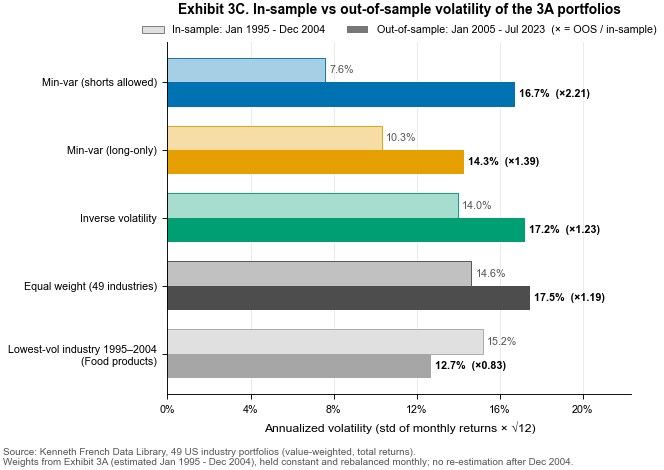

In [9]:
names = [p3.SHORT_LABELS[k].replace("\n", " ") for k in W.columns]
v_in, v_out = list(vol_in.to_numpy()), list(vol_oos.to_numpy())
cols = [p3.PF_COLORS[k] for k in W.columns]
if SHOW_REFERENCE:
    names += ["Equal weight (49 industries)", f"Lowest-vol industry 1995–2004\n({EN[low_ind]})"]
    v_in += list(ref["In-sample 1995–2004"]); v_out += list(ref["Out-of-sample 2005–2023"])
    cols += [config.COLOR_MARKET, "#A6A6A6"]

def lighten(c, a=0.35):
    return mcolors.to_hex(a * np.array(mcolors.to_rgb(c)) + (1 - a))

fig, ax = utils.new_fig("tall")
y = np.arange(len(names))[::-1] * 1.0
h = 0.36
ax.barh(y + h / 2, v_in, height=h, color=[lighten(c) for c in cols], edgecolor=cols, linewidth=0.6)
ax.barh(y - h / 2, v_out, height=h, color=cols)
for yi, a, b in zip(y, v_in, v_out):
    ax.text(a + 0.002, yi + h / 2, f"{a:.1%}", va="center", fontsize=config.FONT_SMALL, color="#555555")
    ax.text(b + 0.002, yi - h / 2, f"{b:.1%}  (×{b / a:.2f})", va="center", fontsize=config.FONT_SMALL,
            fontweight="bold")
ax.set_yticks(y, names)
ax.set_xlim(0, max(v_in + v_out) * 1.28)
utils.percent_axis(ax, "x")
ax.set_xlabel("Annualized volatility (std of monthly returns × √12)")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator
ax.xaxis.set_major_locator(MultipleLocator(0.04))
ax.legend(handles=[Patch(facecolor="#E0E0E0", edgecolor="#777777", linewidth=0.6, label="In-sample: Jan 1995 - Dec 2004"),
                   Patch(facecolor="#777777", label="Out-of-sample: Jan 2005 - Jul 2023  (× = OOS / in-sample)")],
          loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, borderaxespad=0.2)
ax.set_title("Exhibit 3C. In-sample vs out-of-sample volatility of the 3A portfolios", pad=18)
src = (p3.SOURCE_FF49 + "\nWeights from Exhibit 3A (estimated Jan 1995 - Dec 2004), held constant and rebalanced "
       "monthly; no re-estimation after Dec 2004.")
print("PNG →", utils.save_fig(fig, "fig_3C_oos_vol", source=src).relative_to(p3.ROOT))
plt.show()

### 8.2 Supporting chart: rolling 36-month volatility

Plot the annualized volatility over "the previous 36 months" at each point in the out-of-sample period, to check whether the ordering holds **throughout**, not only as an average over the whole period. To keep every window entirely out-of-sample, the lines start in 2007/12 (the first complete 36-month window). The shaded areas are the 2008/09–2009/02 financial crisis and the 2020/02–03 COVID pandemic (the two crisis periods used in 3E).

PNG → output\figures\fig_3C_rolling_vol.png
Share of the 188 rolling windows in which long-only min-var is the lowest of the three: 85%


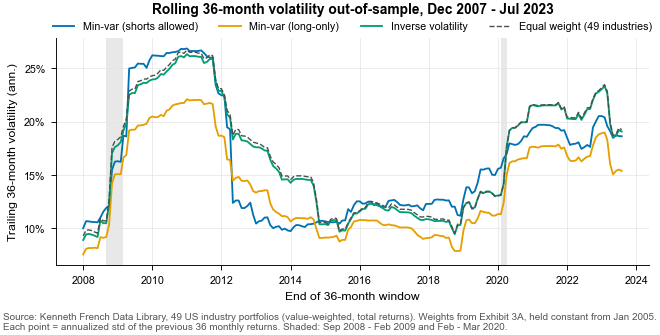

In [10]:
WIN = 36
roll = R_oos.rolling(WIN).std() * np.sqrt(12)
roll_ew = oos.mean(axis=1).rolling(WIN).std() * np.sqrt(12)
roll, roll_ew = roll.dropna(), roll_ew.dropna()
x = roll.index.to_timestamp(how="end")

fig, ax = utils.new_fig("full")
for k in W.columns:
    ax.plot(x, roll[k], color=p3.PF_COLORS[k], label=COLS[k])
if SHOW_REFERENCE:
    ax.plot(x, roll_ew, color=config.COLOR_MARKET, linestyle="--", linewidth=0.9, label="Equal weight (49 industries)")
for a, b in [("2008-09", "2009-02"), ("2020-02", "2020-03")]:
    ax.axvspan(pd.Period(a, "M").to_timestamp(), pd.Period(b, "M").to_timestamp(how="end"), color="#D9D9D9", alpha=0.6, lw=0)
utils.percent_axis(ax, "y")
ax.set_ylabel("Trailing 36-month volatility (ann.)")
ax.set_xlabel("End of 36-month window")
from matplotlib.ticker import MultipleLocator
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.set_title("Rolling 36-month volatility out-of-sample, Dec 2007 - Jul 2023", pad=16)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, borderaxespad=0.2)
src = (p3.SOURCE_FF49 + " Weights from Exhibit 3A, held constant from Jan 2005.\n"
       "Each point = annualized std of the previous 36 monthly returns. Shaded: Sep 2008 - Feb 2009 and Feb - Mar 2020.")
print("PNG →", utils.save_fig(fig, "fig_3C_rolling_vol", source=src).relative_to(p3.ROOT))
share = (roll["mv_long_only"] < roll[["mv_short", "inverse_vol"]].min(axis=1)).mean()
print(f"Share of the {len(roll)} rolling windows in which long-only min-var is the lowest of the three: {share:.0%}")
plt.show()